# Fatores associados ao desempenho no ENEM em escolas privadas

**Pergunta:** entre infraestrutura, porte, seletividade e contexto socioeconômico, o que mais se associa à nota média do ENEM de uma escola privada — e o que a escola pode de fato mudar?

**Base:** 4.433 escolas privadas com ≥10 participantes no ENEM (média 2024+2025), a partir de dados públicos (Censo Escolar INEP 2025, microdados ENEM 2024/2025, Censo IBGE 2022). Escolas de educação especial, alternância e "salas vitrine" já foram removidas em `src/01_preparar_dados.py`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED = 42
ALVO = "enem_media_2anos"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/escolas_modelo.csv")
print(df.shape)
df.head(3)

(4433, 15)


,codigo_escola,nome_escola,codigo_municipio,cidade,uf,enem_media_2anos,enem_2025,enem_2024,participantes_2025,participantes_2024,matriculas_medio,indice_infra,exame_selecao,renda_mediana_responsavel,categoria_privada
0,11013737,COLEGIO ADVENTISTA DE JI-PARANA,1100122,Ji-Paraná,RO,573.082581,566.343333,583.282523,56.0,37.0,210.0,4.0,0.0,2000.0,4.0
1,11037660,COLEGIO UNIAO,1100122,Ji-Paraná,RO,609.506829,590.138889,624.664348,18.0,23.0,67.0,1.0,0.0,2500.0,1.0
2,11000058,CENTRO DE ENSINO CLASSE A,1100205,Porto Velho,RO,640.085340,644.628722,634.094066,120.0,91.0,357.0,4.0,0.0,2600.0,1.0


## 1. Conhecendo a base

In [2]:
print("Nulos por coluna:", df.isna().sum()[df.isna().sum() > 0].to_dict())
df[[ALVO, "indice_infra", "matriculas_medio", "renda_mediana_responsavel", "exame_selecao"]].describe().round(1).T

Nulos por coluna: {'enem_2024': 441, 'participantes_2024': 441, 'exame_selecao': 11}


,count,mean,std,min,25%,50%,75%,max
enem_media_2anos,4433.0,603.1,45.2,464.4,569.4,599.9,634.3,777.5
indice_infra,4433.0,3.4,1.4,0.0,2.0,4.0,5.0,5.0
matriculas_medio,4433.0,156.3,134.1,7.0,74.0,115.0,189.0,1403.0
renda_mediana_responsavel,4433.0,3208.5,2147.2,1200.0,2000.0,2500.0,4000.0,17000.0
exame_selecao,4422.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0


Pontos de atenção (checados antes de modelar): `exame_selecao` tem 11 nulos (o INEP usa código 9 para "não se aplica", recodificado como nulo); `enem_2024` falta em 441 escolas (para elas a média de 2 anos é só 2025); e a renda é a **mediana do responsável no bairro da escola** (ou no distrito, quando o bairro não casa) — não a renda das famílias da escola. A renda varia bastante dentro dos municípios (71% da variância é intra-município), mas escolas da mesma cidade costumam compartilhar o mesmo valor (23% das escolas estão em municípios com um único valor).

## 2. Análise exploratória

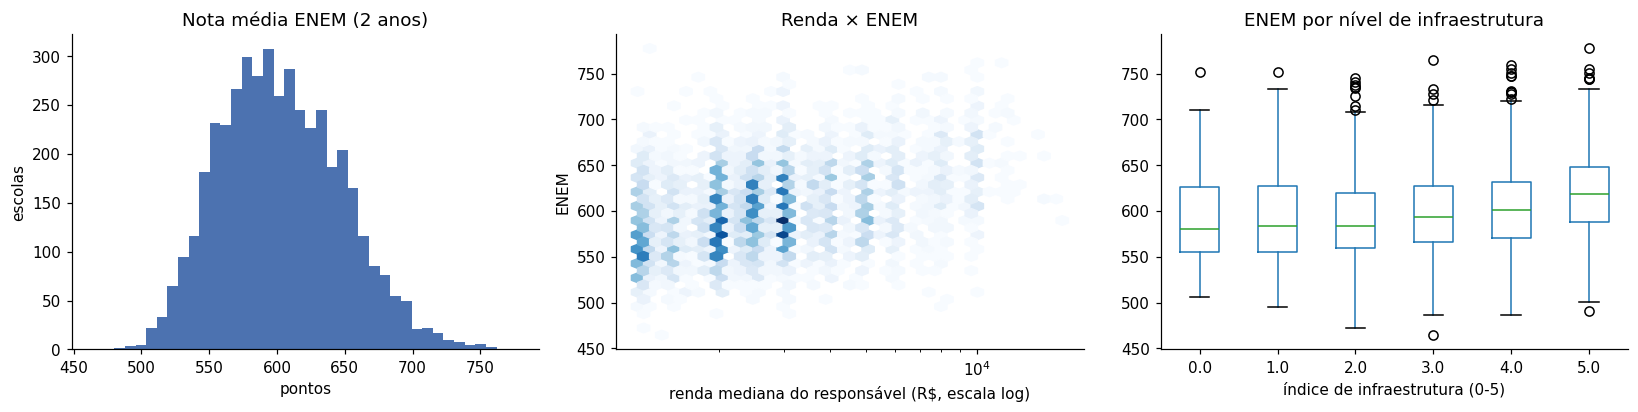

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df[ALVO], bins=40, color="#4C72B0"); ax[0].set(title="Nota média ENEM (2 anos)", xlabel="pontos", ylabel="escolas")
ax[1].hexbin(df["renda_mediana_responsavel"], df[ALVO], gridsize=35, cmap="Blues", mincnt=1, xscale="log")
ax[1].set(title="Renda × ENEM", xlabel="renda mediana do responsável (R$, escala log)", ylabel="ENEM")
df.boxplot(column=ALVO, by="indice_infra", ax=ax[2], grid=False); ax[2].set(title="ENEM por nível de infraestrutura", xlabel="índice de infraestrutura (0-5)", ylabel="")
plt.suptitle(""); plt.tight_layout(); plt.savefig("../outputs/figuras/eda.png", bbox_inches="tight"); plt.show()

In [4]:
VARS = ["indice_infra", "renda_mediana_responsavel", "matriculas_medio", "exame_selecao"]
print("Correlação com o ENEM e entre as variáveis:")
display(df[[ALVO] + VARS].corr().round(2))

d_vif = df.dropna(subset=VARS)
X_vif = sm.add_constant(d_vif[VARS])
vif = pd.Series([variance_inflation_factor(X_vif.values, i + 1) for i in range(len(VARS))], index=VARS).round(2)
print("VIF (acima de ~5 indicaria multicolinearidade problemática):"); display(vif.to_frame("VIF"))

Correlação com o ENEM e entre as variáveis:


,enem_media_2anos,indice_infra,renda_mediana_responsavel,matriculas_medio,exame_selecao
enem_media_2anos,1.00,0.21,0.34,0.31,0.21
indice_infra,0.21,1.00,0.09,0.15,0.12
renda_mediana_responsavel,0.34,0.09,1.00,0.18,0.14
matriculas_medio,0.31,0.15,0.18,1.00,0.12
exame_selecao,0.21,0.12,0.14,0.12,1.00


VIF (acima de ~5 indicaria multicolinearidade problemática):


,VIF
indice_infra,1.04
renda_mediana_responsavel,1.05
matriculas_medio,1.06
exame_selecao,1.04


As correlações com o ENEM são todas positivas e moderadas (renda é a maior), e os VIFs ficam perto de 1: os fatores trazem informação própria, então os coeficientes do modelo podem ser lidos separadamente.

## 3. Modelagem com validação de verdade

O alvo é contínuo, então o ponto de partida é regressão linear, comparada a um baseline (prever sempre a média) e a um Random Forest (captura não linearidades). Duas decisões metodológicas:

- **Porte em log:** matrículas têm distribuição muito assimétrica (7 a 1.403).
- **Validação agrupada por município (`GroupKFold`):** escolas da mesma cidade compartilham contexto (e muitas vezes o mesmo valor de renda); se caíssem em treino e teste, o modelo "decoraria" a cidade e o R² ficaria inflado. Agrupar por município testa o modelo em cidades que ele não viu. Mostro também a validação aleatória só para quantificar esse efeito.

In [5]:
def preparar_modelagem(df: pd.DataFrame) -> pd.DataFrame:
    """Remove nulos nas variáveis do modelo e cria o log do porte."""
    d = df.dropna(subset=[ALVO] + VARS).reset_index(drop=True)
    d["log_matriculas"] = np.log1p(d["matriculas_medio"])
    return d

def metricas(y, p) -> dict:
    return {"R2": r2_score(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "MAE": mean_absolute_error(y, p)}

d = preparar_modelagem(df)
FEATS = ["indice_infra", "renda_mediana_responsavel", "log_matriculas", "exame_selecao"]
X, y, grupos = d[FEATS], d[ALVO], d["codigo_municipio"]
print(f"{len(d)} escolas na modelagem ({len(df) - len(d)} sem exame_selecao), {grupos.nunique()} municípios")

modelos = {
    "Baseline (média)": DummyRegressor(),
    "Regressão linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}
linhas, oof = [], {}
for nome, m in modelos.items():
    p_grupo = cross_val_predict(m, X, y, groups=grupos, cv=GroupKFold(5))
    p_aleat = cross_val_predict(m, X, y, cv=KFold(5, shuffle=True, random_state=SEED))
    oof[nome] = p_grupo
    linhas.append({"modelo": nome, **{f"{k} (agrupada)": v for k, v in metricas(y, p_grupo).items()}, "R2 (aleatória)": r2_score(y, p_aleat)})
resultado_cv = pd.DataFrame(linhas).set_index("modelo").round(3)
resultado_cv

4422 escolas na modelagem (11 sem exame_selecao), 311 municípios


,R2 (agrupada),RMSE (agrupada),MAE (agrupada),R2 (aleatória)
modelo,,,,
Baseline (média),-0.003,45.308,36.838,-0.001
Regressão linear,0.224,39.866,31.910,0.227
Random Forest,0.205,40.339,32.211,0.224


A regressão linear reduz o erro do baseline (RMSE ~45 → ~40 pontos) e o Random Forest **não melhora** — sinal de que a relação é essencialmente linear e de que o teto de ~22% de R² vem de fatores não medidos aqui, não de falta de flexibilidade do modelo. A diferença entre a validação aleatória e a agrupada no Random Forest mostra o vazamento por cidade que a validação agrupada evita.

## 4. O que pesa mais?

In [6]:
# Coeficientes padronizados (comparáveis entre si), com erros-padrão robustos (HC3)
Z = (X - X.mean()) / X.std(); zy = (y - y.mean()) / y.std()
padr = sm.OLS(zy, sm.add_constant(Z)).fit(cov_type="HC3")
# Coeficientes brutos (em pontos de ENEM por unidade)
bruto = sm.OLS(y, sm.add_constant(X)).fit(cov_type="HC3")

# Importância por permutação do Random Forest, medida em dados de teste (queda de R² ao embaralhar a variável)
imp = []
for tr, te in GroupKFold(5).split(X, y, grupos):
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(X.iloc[tr], y.iloc[tr])
    imp.append(permutation_importance(rf, X.iloc[te], y.iloc[te], n_repeats=10, random_state=SEED, scoring="r2").importances_mean)

nomes = {"indice_infra": "Infraestrutura", "renda_mediana_responsavel": "Renda do responsável", "log_matriculas": "Porte (log matrículas)", "exame_selecao": "Exame de seleção"}
coef = pd.DataFrame({
    "variavel": [nomes[f] for f in FEATS],
    "coef_padronizado": padr.params[FEATS].values,
    "p_valor": padr.pvalues[FEATS].values,
    "coef_bruto_pontos": bruto.params[FEATS].values,
    "ic95_inf": bruto.conf_int().loc[FEATS, 0].values,
    "ic95_sup": bruto.conf_int().loc[FEATS, 1].values,
    "importancia_permutacao_rf": np.mean(imp, axis=0),
}).sort_values("coef_padronizado", ascending=False).round(4)
coef

,variavel,coef_padronizado,p_valor,coef_bruto_pontos,ic95_inf,ic95_sup,importancia_permutacao_rf
1,Renda do responsável,0.2753,0.0,0.0058,0.0052,0.0064,0.1929
2,Porte (log matrículas),0.2448,0.0,16.3260,14.3373,18.3148,0.1565
3,Exame de seleção,0.1337,0.0,14.7388,11.5735,17.9041,0.0376
0,Infraestrutura,0.1246,0.0,4.0750,3.1753,4.9747,0.0501


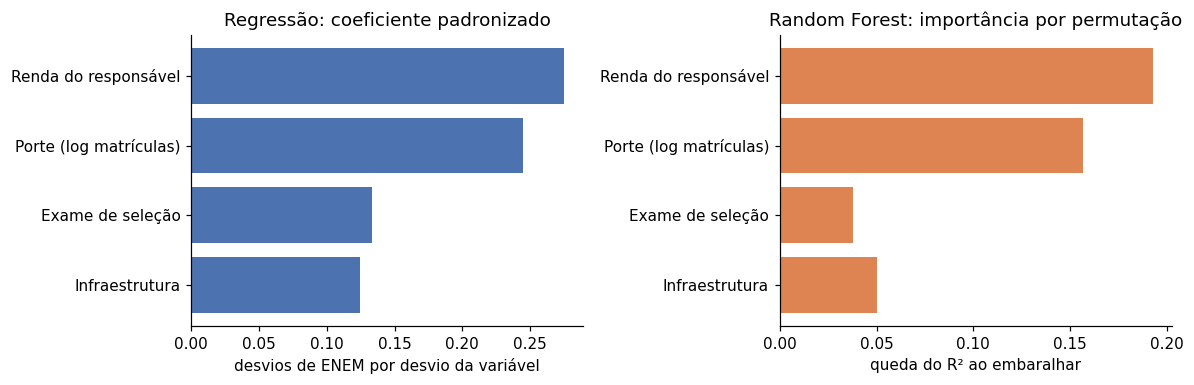

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
c = coef.sort_values("coef_padronizado")
ax[0].barh(c["variavel"], c["coef_padronizado"], color="#4C72B0"); ax[0].set(title="Regressão: coeficiente padronizado", xlabel="desvios de ENEM por desvio da variável")
ax[1].barh(c["variavel"], c["importancia_permutacao_rf"], color="#DD8452"); ax[1].set(title="Random Forest: importância por permutação", xlabel="queda do R² ao embaralhar")
plt.tight_layout(); plt.savefig("../outputs/figuras/importancia.png", bbox_inches="tight"); plt.show()

Os dois métodos, independentes, apontam a **mesma ordem**: renda do responsável > porte > exame de seleção ≈ infraestrutura (no Random Forest, infraestrutura fica um pouco acima do exame). Todos os coeficientes são significativos (p < 0,001). Infraestrutura — o fator que a escola mais controla — fica entre os de menor peso, junto com a seletividade.

## 5. Robustez

Três checagens contra explicações alternativas: (a) as duas maiores cidades (São Paulo e Rio) estariam guiando o resultado?; (b) escolas com só um ano de ENEM distorcem?; (c) os efeitos seriam apenas diferenças entre cidades? Para (c), o modelo com **efeitos fixos de município** compara só escolas da mesma cidade, mantendo a renda do bairro/distrito.

In [8]:
def r2_cv(sub: pd.DataFrame) -> float:
    p = cross_val_predict(LinearRegression(), sub[FEATS], sub[ALVO], groups=sub["codigo_municipio"], cv=GroupKFold(5))
    return r2_score(sub[ALVO], p)

rob = pd.DataFrame([
    {"cenário": "Modelo principal", "escolas": len(d), "R2 (CV agrupada)": r2_cv(d)},
    {"cenário": "Sem São Paulo e Rio", "escolas": int((~d.cidade.isin(["São Paulo", "Rio de Janeiro"])).sum()), "R2 (CV agrupada)": r2_cv(d[~d.cidade.isin(["São Paulo", "Rio de Janeiro"])])},
    {"cenário": "Só escolas com ENEM 2024 e 2025", "escolas": int(d.enem_2024.notna().sum()), "R2 (CV agrupada)": r2_cv(d[d.enem_2024.notna()])},
]).round(3)
display(rob)

# Efeitos fixos de município: cada cidade tem seu próprio nível; os coeficientes passam a refletir só diferenças entre escolas da mesma cidade
n_por_mun = d["codigo_municipio"].value_counts(); fe = d[d["codigo_municipio"].isin(n_por_mun[n_por_mun >= 2].index)]
cl = {"cov_type": "cluster", "cov_kwds": {"groups": fe["codigo_municipio"]}}
base_f = f"{ALVO} ~ indice_infra + log_matriculas + exame_selecao + renda_mediana_responsavel"
m_fe = smf.ols(base_f + " + C(codigo_municipio)", fe).fit(**cl)
m_pool = smf.ols(base_f, fe).fit(**cl)
comp = pd.DataFrame({"pooled (todas as escolas)": m_pool.params, "efeitos fixos de município": m_fe.params}).loc[["indice_infra", "log_matriculas", "exame_selecao", "renda_mediana_responsavel"]].round(4)
comp.index = ["Infraestrutura (pts por nível)", "Porte (pts por unidade de log)", "Exame de seleção (pts)", "Renda (pts por R$ 1)"]
comp

,cenário,escolas,R2 (CV agrupada)
0,Modelo principal,4422,0.224
1,Sem São Paulo e Rio,3581,0.207
2,Só escolas com ENEM 2024 e 2025,3986,0.209


,pooled (todas as escolas),efeitos fixos de município
Infraestrutura (pts por nível),4.0558,3.7481
Porte (pts por unidade de log),16.3710,16.5153
Exame de seleção (pts),14.7007,13.8744
Renda (pts por R$ 1),0.0058,0.0067


O desempenho do modelo se mantém (R² de ~0,21 a ~0,22) nos três cenários, e os efeitos de infraestrutura, porte, seletividade e renda **mudam pouco quando se comparam só escolas da mesma cidade** — a renda do bairro/distrito segue com efeito positivo (≈ +6 a +7 pontos por R$ 1.000) mesmo dentro da cidade, então não são um artefato de "cidade rica vs. cidade pobre".

## 6. Escolas acima e abaixo do esperado + simulação

O resíduo da validação cruzada (nota real − nota prevista por um modelo que **não viu** aquela cidade) mostra quais escolas rendem menos ou mais do que o perfil sugere. Não é um julgamento de qualidade: o modelo explica só ~22% da variação, então resíduo grande também pode ser fator não medido ou ruído de amostra pequena.

In [9]:
d["previsto_cv"] = oof["Regressão linear"]
d["residuo_cv"] = d[ALVO] - d["previsto_cv"]
print(f"Desvio-padrão do resíduo: {d['residuo_cv'].std():.1f} pontos")

# Candidatas: infraestrutura baixa (<=2), porte médio, resíduo mais negativo
abaixo = d[(d.indice_infra <= 2) & d.matriculas_medio.between(50, 300)].nsmallest(5, "residuo_cv")
b_infra = bruto.params["indice_infra"]; ic = bruto.conf_int().loc["indice_infra"]
whatif = abaixo[["nome_escola", "cidade", "uf", "indice_infra", ALVO, "previsto_cv", "residuo_cv"]].copy()
whatif["ganho_estimado_+2_infra"] = 2 * b_infra
whatif["ic95_inf"], whatif["ic95_sup"] = 2 * ic[0], 2 * ic[1]
display(whatif.round(1))
print(f"Subir 2 níveis de infraestrutura: +{2*b_infra:.1f} pontos (IC95%: {2*ic[0]:.1f} a {2*ic[1]:.1f}), mantendo renda, porte e seletividade.")

Desvio-padrão do resíduo: 39.9 pontos


,nome_escola,cidade,uf,indice_infra,enem_media_2anos,previsto_cv,residuo_cv,ganho_estimado_+2_infra,ic95_inf,ic95_sup
1694,COL VITAL BRASIL,Niterói,RJ,2.0,501.5,631.9,-130.4,8.1,6.4,9.9
3075,PAULICEIA COLEGIO,São Paulo,SP,2.0,498.9,615.7,-116.8,8.1,6.4,9.9
984,COLEGIO OBJETIVA RAMILI,Alagoinhas,BA,2.0,472.3,571.2,-98.9,8.1,6.4,9.9
1840,COLEGIO PINHEIRO GUIMARAES LTDA,Rio de Janeiro,RJ,2.0,536.9,626.7,-89.8,8.1,6.4,9.9
1862,EXTERNATO PINHEIRO LTDA,Rio de Janeiro,RJ,2.0,509.1,596.6,-87.5,8.1,6.4,9.9


Subir 2 níveis de infraestrutura: +8.1 pontos (IC95%: 6.4 a 9.9), mantendo renda, porte e seletividade.


O ganho estimado é real e estatisticamente distinguível de zero, mas pequeno frente à dispersão entre escolas (desvio-padrão do resíduo ≈ 40 pontos). É uma **associação** em dados observacionais, não uma promessa de retorno causal de investir em infraestrutura.

## 7. Exportando para o Looker Studio

In [10]:
d["faixa_infra"] = d["indice_infra"].astype(int)
cols = ["codigo_escola", "nome_escola", "cidade", "uf", ALVO, "indice_infra", "faixa_infra", "matriculas_medio",
        "renda_mediana_responsavel", "exame_selecao", "previsto_cv", "residuo_cv"]
d[cols].round(2).to_csv("../outputs/escolas_resultados.csv", index=False)
coef.to_csv("../outputs/coeficientes.csv", index=False)
resultado_cv.reset_index().to_csv("../outputs/metricas_modelos.csv", index=False)
whatif.round(2).to_csv("../outputs/whatif_infra.csv", index=False)
rob.to_csv("../outputs/robustez.csv", index=False)
print("Arquivos salvos em ../outputs/:", ["escolas_resultados.csv", "coeficientes.csv", "metricas_modelos.csv", "whatif_infra.csv", "robustez.csv"])

Arquivos salvos em ../outputs/: ['escolas_resultados.csv', 'coeficientes.csv', 'metricas_modelos.csv', 'whatif_infra.csv', 'robustez.csv']


## 8. Conclusões

1. **Contexto socioeconômico e porte pesam mais que infraestrutura.** Renda (0,28 desvio-padrão) e porte (0,24) se associam mais ao ENEM do que exame de seleção (0,13) ou infraestrutura (0,12) — ordem confirmada por dois métodos distintos.
2. **O que a escola controla importa, mas pouco.** Dois níveis a mais de infraestrutura se associam a ~+8 pontos de ENEM (IC95% ≈ 6 a 10), contra um desvio-padrão de ~40 pontos entre escolas.
3. **O modelo é honesto sobre o próprio limite.** R² fora da amostra ≈ 0,22: a maior parte da variação vem de fatores não medidos (corpo docente, perfil do aluno ingressante, tradição da escola). Random Forest não melhora o resultado, então o limite está nos dados, não no método.

**Limitações:** base observacional (nada aqui prova causalidade); renda medida no bairro/distrito da escola, não por família (a renda do aluno não é observada); escolas com poucos participantes têm média ruidosa; exemplos de resíduo foram checados contra riscos conhecidos (educação especial, salas vitrine), não contra todos os possíveis artefatos.